In [1]:
%pip install nltk matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist
import matplotlib.pyplot as plt

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to /home/baltej/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /home/baltej/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /home/baltej/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [3]:
text = """Cricket is more than just a sport in India, it is an emotion that unites millions of people. 
I still remember watching the 2011 World Cup final with my family, cheering loudly for every single run. 
The thrill of a last-over finish can make even the calmest person's heart race! 
Players like Virat Kohli and Rohit Sharma inspire young kids to practice for hours in dusty streets and local grounds. 
Whether it's a Test match, an ODI, or a T20 game, cricket teaches patience, teamwork, and never giving up. 
That is why cricket will always be my favorite game."""

print("Original Text:\n")
print(text)

Original Text:

Cricket is more than just a sport in India, it is an emotion that unites millions of people. 
I still remember watching the 2011 World Cup final with my family, cheering loudly for every single run. 
The thrill of a last-over finish can make even the calmest person's heart race! 
Players like Virat Kohli and Rohit Sharma inspire young kids to practice for hours in dusty streets and local grounds. 
Whether it's a Test match, an ODI, or a T20 game, cricket teaches patience, teamwork, and never giving up. 
That is why cricket will always be my favorite game.


In [4]:
lower_text = text.lower()

# Remove everything except letters, digits and whitespace
clean_text = re.sub(r'[^\w\s]', '', lower_text)

# Collapse extra whitespace/newlines
clean_text = re.sub(r'\s+', ' ', clean_text).strip()

print("Cleaned Text:\n")
print(clean_text)

Cleaned Text:

cricket is more than just a sport in india it is an emotion that unites millions of people i still remember watching the 2011 world cup final with my family cheering loudly for every single run the thrill of a lastover finish can make even the calmest persons heart race players like virat kohli and rohit sharma inspire young kids to practice for hours in dusty streets and local grounds whether its a test match an odi or a t20 game cricket teaches patience teamwork and never giving up that is why cricket will always be my favorite game


In [5]:
# Sentence tokenization (use ORIGINAL text, since punctuation marks sentence ends)
sentences = sent_tokenize(text)
print("Sentence Tokens:")
for i, s in enumerate(sentences, 1):
    print(f"{i}. {s.strip()}")

print("\nTotal sentences:", len(sentences))

# Word tokenization (on cleaned text)
words = word_tokenize(clean_text)
print("\nWord Tokens:")
print(words)
print("\nTotal words:", len(words))

Sentence Tokens:
1. Cricket is more than just a sport in India, it is an emotion that unites millions of people.
2. I still remember watching the 2011 World Cup final with my family, cheering loudly for every single run.
3. The thrill of a last-over finish can make even the calmest person's heart race!
4. Players like Virat Kohli and Rohit Sharma inspire young kids to practice for hours in dusty streets and local grounds.
5. Whether it's a Test match, an ODI, or a T20 game, cricket teaches patience, teamwork, and never giving up.
6. That is why cricket will always be my favorite game.

Total sentences: 6

Word Tokens:
['cricket', 'is', 'more', 'than', 'just', 'a', 'sport', 'in', 'india', 'it', 'is', 'an', 'emotion', 'that', 'unites', 'millions', 'of', 'people', 'i', 'still', 'remember', 'watching', 'the', '2011', 'world', 'cup', 'final', 'with', 'my', 'family', 'cheering', 'loudly', 'for', 'every', 'single', 'run', 'the', 'thrill', 'of', 'a', 'lastover', 'finish', 'can', 'make', 'even'

In [6]:
# Use the ORIGINAL text (with punctuation) to see the real difference
split_tokens = text.split()
nltk_tokens = word_tokenize(text)

print("Using split():")
print(split_tokens[:25])
print("Count:", len(split_tokens))

print("\nUsing word_tokenize():")
print(nltk_tokens[:25])
print("Count:", len(nltk_tokens))

# Show tokens that differ
print("\nTokens only in split():", set(split_tokens) - set(nltk_tokens))
print("\nTokens only in word_tokenize():", set(nltk_tokens) - set(split_tokens))

Using split():
['Cricket', 'is', 'more', 'than', 'just', 'a', 'sport', 'in', 'India,', 'it', 'is', 'an', 'emotion', 'that', 'unites', 'millions', 'of', 'people.', 'I', 'still', 'remember', 'watching', 'the', '2011', 'World']
Count: 99

Using word_tokenize():
['Cricket', 'is', 'more', 'than', 'just', 'a', 'sport', 'in', 'India', ',', 'it', 'is', 'an', 'emotion', 'that', 'unites', 'millions', 'of', 'people', '.', 'I', 'still', 'remember', 'watching', 'the']
Count: 114

Tokens only in split(): {'run.', 'family,', 'patience,', "it's", 'race!', 'India,', 'up.', 'teamwork,', 'game,', "person's", 'match,', 'people.', 'game.', 'ODI,', 'grounds.'}

Tokens only in word_tokenize(): {'run', 'ODI', 'race', ',', 'teamwork', 'up', 'person', 'people', 'India', 'family', "'s", '!', 'patience', 'match', '.', 'game', 'grounds'}


In [7]:
sample = "Don't stop, it's India's game! Rohit scored 100."
print("split()        :", sample.split())
print("word_tokenize():", word_tokenize(sample))

split()        : ["Don't", 'stop,', "it's", "India's", 'game!', 'Rohit', 'scored', '100.']
word_tokenize(): ['Do', "n't", 'stop', ',', 'it', "'s", 'India', "'s", 'game', '!', 'Rohit', 'scored', '100', '.']


In [8]:
stop_words = set(stopwords.words('english'))

# Use word tokens from the cleaned text
filtered_words = [w for w in words if w not in stop_words]

print("Words before stopword removal:", len(words))
print("Words after stopword removal :", len(filtered_words))
print("\nStopwords removed:", [w for w in words if w in stop_words])
print("\nFiltered words:\n", filtered_words)

Words before stopword removal: 99
Words after stopword removal : 60

Stopwords removed: ['is', 'more', 'than', 'just', 'a', 'in', 'it', 'is', 'an', 'that', 'of', 'i', 'the', 'with', 'my', 'for', 'the', 'of', 'a', 'can', 'the', 'and', 'to', 'for', 'in', 'and', 'its', 'a', 'an', 'or', 'a', 'and', 'up', 'that', 'is', 'why', 'will', 'be', 'my']

Filtered words:
 ['cricket', 'sport', 'india', 'emotion', 'unites', 'millions', 'people', 'still', 'remember', 'watching', '2011', 'world', 'cup', 'final', 'family', 'cheering', 'loudly', 'every', 'single', 'run', 'thrill', 'lastover', 'finish', 'make', 'even', 'calmest', 'persons', 'heart', 'race', 'players', 'like', 'virat', 'kohli', 'rohit', 'sharma', 'inspire', 'young', 'kids', 'practice', 'hours', 'dusty', 'streets', 'local', 'grounds', 'whether', 'test', 'match', 'odi', 't20', 'game', 'cricket', 'teaches', 'patience', 'teamwork', 'never', 'giving', 'cricket', 'always', 'favorite', 'game']


In [9]:
fdist = FreqDist(filtered_words)

print("Word Frequency (excluding stopwords):\n")
for word, freq in fdist.most_common():
    print(f"{word:15} {freq}")

print("\nTop 5 words:", fdist.most_common(5))

Word Frequency (excluding stopwords):

cricket         3
game            2
sport           1
india           1
emotion         1
unites          1
millions        1
people          1
still           1
remember        1
watching        1
2011            1
world           1
cup             1
final           1
family          1
cheering        1
loudly          1
every           1
single          1
run             1
thrill          1
lastover        1
finish          1
make            1
even            1
calmest         1
persons         1
heart           1
race            1
players         1
like            1
virat           1
kohli           1
rohit           1
sharma          1
inspire         1
young           1
kids            1
practice        1
hours           1
dusty           1
streets         1
local           1
grounds         1
whether         1
test            1
match           1
odi             1
t20             1
teaches         1
patience        1
teamwork        1
never  

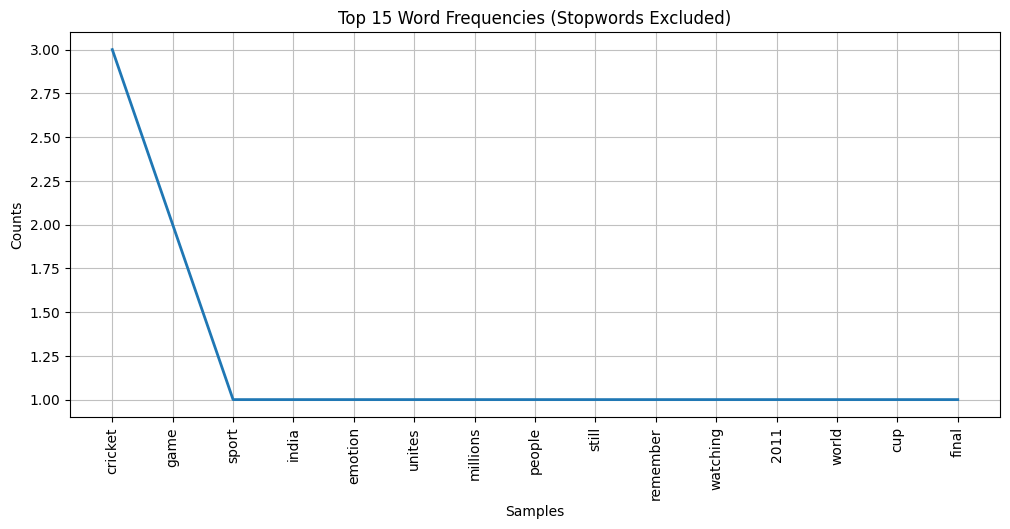

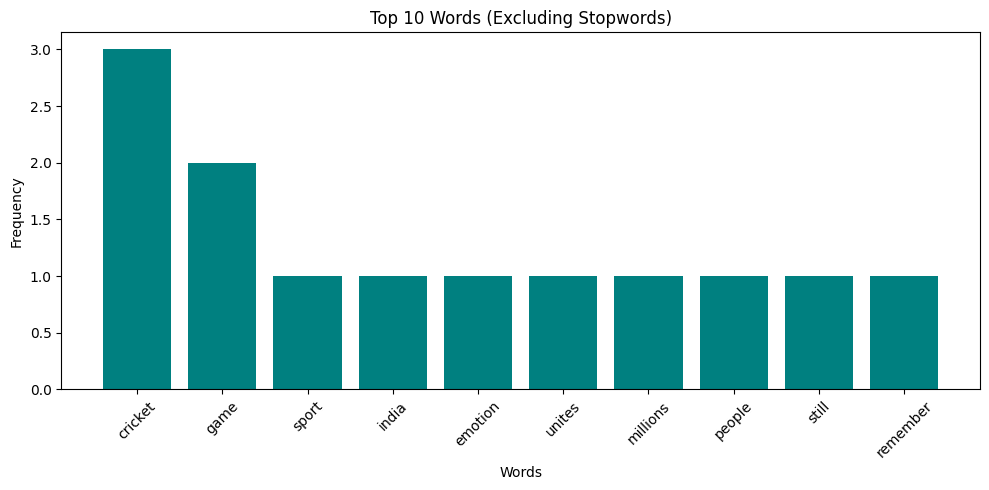

In [10]:
plt.figure(figsize=(12, 5))
fdist.plot(15, cumulative=False, title="Top 15 Word Frequencies (Stopwords Excluded)")
plt.show()

# Bar chart alternative
top = fdist.most_common(10)
labels, counts = zip(*top)

plt.figure(figsize=(10, 5))
plt.bar(labels, counts, color='teal')
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.title("Top 10 Words (Excluding Stopwords)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [11]:
 # 2nd Answer
# Lowercase first so "Cricket" and "cricket" are treated the same
alpha_words = re.findall(r'[a-z]+', text.lower())

print("Alphabet-only words:\n")
print(alpha_words)
print("\nTotal:", len(alpha_words))

Alphabet-only words:

['cricket', 'is', 'more', 'than', 'just', 'a', 'sport', 'in', 'india', 'it', 'is', 'an', 'emotion', 'that', 'unites', 'millions', 'of', 'people', 'i', 'still', 'remember', 'watching', 'the', 'world', 'cup', 'final', 'with', 'my', 'family', 'cheering', 'loudly', 'for', 'every', 'single', 'run', 'the', 'thrill', 'of', 'a', 'last', 'over', 'finish', 'can', 'make', 'even', 'the', 'calmest', 'person', 's', 'heart', 'race', 'players', 'like', 'virat', 'kohli', 'and', 'rohit', 'sharma', 'inspire', 'young', 'kids', 'to', 'practice', 'for', 'hours', 'in', 'dusty', 'streets', 'and', 'local', 'grounds', 'whether', 'it', 's', 'a', 'test', 'match', 'an', 'odi', 'or', 'a', 't', 'game', 'cricket', 'teaches', 'patience', 'teamwork', 'and', 'never', 'giving', 'up', 'that', 'is', 'why', 'cricket', 'will', 'always', 'be', 'my', 'favorite', 'game']

Total: 101


In [12]:
stop_words = set(stopwords.words('english'))

filtered = [w for w in alpha_words if w not in stop_words]

print("Before:", len(alpha_words), "| After:", len(filtered))
print("\nFiltered words:\n", filtered)

Before: 101 | After: 58

Filtered words:
 ['cricket', 'sport', 'india', 'emotion', 'unites', 'millions', 'people', 'still', 'remember', 'watching', 'world', 'cup', 'final', 'family', 'cheering', 'loudly', 'every', 'single', 'run', 'thrill', 'last', 'finish', 'make', 'even', 'calmest', 'person', 'heart', 'race', 'players', 'like', 'virat', 'kohli', 'rohit', 'sharma', 'inspire', 'young', 'kids', 'practice', 'hours', 'dusty', 'streets', 'local', 'grounds', 'whether', 'test', 'match', 'odi', 'game', 'cricket', 'teaches', 'patience', 'teamwork', 'never', 'giving', 'cricket', 'always', 'favorite', 'game']


In [15]:
from nltk.stem import PorterStemmer
stemmer = PorterStemmer()
stemmed = [stemmer.stem(w) for w in filtered]

print("Stemmed words:\n")
print(stemmed)

Stemmed words:

['cricket', 'sport', 'india', 'emot', 'unit', 'million', 'peopl', 'still', 'rememb', 'watch', 'world', 'cup', 'final', 'famili', 'cheer', 'loudli', 'everi', 'singl', 'run', 'thrill', 'last', 'finish', 'make', 'even', 'calmest', 'person', 'heart', 'race', 'player', 'like', 'virat', 'kohli', 'rohit', 'sharma', 'inspir', 'young', 'kid', 'practic', 'hour', 'dusti', 'street', 'local', 'ground', 'whether', 'test', 'match', 'odi', 'game', 'cricket', 'teach', 'patienc', 'teamwork', 'never', 'give', 'cricket', 'alway', 'favorit', 'game']


In [18]:
from nltk.stem import WordNetLemmatizer
lemmatizer = WordNetLemmatizer()

# Default: treats every word as a noun
lemmatized_noun = [lemmatizer.lemmatize(w) for w in filtered]

# Better: tell it the word is a verb
lemmatized_verb = [lemmatizer.lemmatize(w, pos='v') for w in filtered]

print("Lemmatized (noun, default):\n", lemmatized_noun)
print("\nLemmatized (verb):\n", lemmatized_verb)

Lemmatized (noun, default):
 ['cricket', 'sport', 'india', 'emotion', 'unites', 'million', 'people', 'still', 'remember', 'watching', 'world', 'cup', 'final', 'family', 'cheering', 'loudly', 'every', 'single', 'run', 'thrill', 'last', 'finish', 'make', 'even', 'calmest', 'person', 'heart', 'race', 'player', 'like', 'virat', 'kohli', 'rohit', 'sharma', 'inspire', 'young', 'kid', 'practice', 'hour', 'dusty', 'street', 'local', 'ground', 'whether', 'test', 'match', 'odi', 'game', 'cricket', 'teach', 'patience', 'teamwork', 'never', 'giving', 'cricket', 'always', 'favorite', 'game']

Lemmatized (verb):
 ['cricket', 'sport', 'india', 'emotion', 'unite', 'millions', 'people', 'still', 'remember', 'watch', 'world', 'cup', 'final', 'family', 'cheer', 'loudly', 'every', 'single', 'run', 'thrill', 'last', 'finish', 'make', 'even', 'calmest', 'person', 'heart', 'race', 'players', 'like', 'virat', 'kohli', 'rohit', 'sharma', 'inspire', 'young', 'kid', 'practice', 'hours', 'dusty', 'streets', 'loca

In [20]:
from nltk.corpus import wordnet
nltk.download('averaged_perceptron_tagger')
nltk.download('averaged_perceptron_tagger_eng')

def get_wordnet_pos(tag):
    if tag.startswith('J'): return wordnet.ADJ
    if tag.startswith('V'): return wordnet.VERB
    if tag.startswith('R'): return wordnet.ADV
    return wordnet.NOUN

tagged = nltk.pos_tag(filtered)
lemmatized_pos = [lemmatizer.lemmatize(w, get_wordnet_pos(t)) for w, t in tagged]

print("POS-aware lemmas:\n", lemmatized_pos)

POS-aware lemmas:
 ['cricket', 'sport', 'india', 'emotion', 'unite', 'million', 'people', 'still', 'remember', 'watch', 'world', 'cup', 'final', 'family', 'cheer', 'loudly', 'every', 'single', 'run', 'thrill', 'last', 'finish', 'make', 'even', 'calm', 'person', 'heart', 'race', 'player', 'like', 'virat', 'kohli', 'rohit', 'sharma', 'inspire', 'young', 'kid', 'practice', 'hour', 'dusty', 'street', 'local', 'ground', 'whether', 'test', 'match', 'odi', 'game', 'cricket', 'teach', 'patience', 'teamwork', 'never', 'give', 'cricket', 'always', 'favorite', 'game']


[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /home/baltej/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /home/baltej/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


In [21]:
import pandas as pd

df = pd.DataFrame({
    'Original': filtered,
    'Stemmed': stemmed,
    'Lemma (noun)': lemmatized_noun,
    'Lemma (verb)': lemmatized_verb,
    'Lemma (POS-aware)': lemmatized_pos
})

print(df.to_string())

# Show only the rows where stem and lemma differ
print("\nWords where stemming and lemmatization differ:\n")
print(df[df['Stemmed'] != df['Lemma (POS-aware)']].to_string())

    Original   Stemmed Lemma (noun) Lemma (verb) Lemma (POS-aware)
0    cricket   cricket      cricket      cricket           cricket
1      sport     sport        sport        sport             sport
2      india     india        india        india             india
3    emotion      emot      emotion      emotion           emotion
4     unites      unit       unites        unite             unite
5   millions   million      million     millions           million
6     people     peopl       people       people            people
7      still     still        still        still             still
8   remember    rememb     remember     remember          remember
9   watching     watch     watching        watch             watch
10     world     world        world        world             world
11       cup       cup          cup          cup               cup
12     final     final        final        final             final
13    family    famili       family       family            fa

In [22]:
print("Unique original words :", len(set(filtered)))
print("Unique stems          :", len(set(stemmed)))
print("Unique lemmas         :", len(set(lemmatized_pos)))

Unique original words : 55
Unique stems          : 55
Unique lemmas         : 55


In [ ]:
# Answer: Prefer stemming when speed matters and exact word form doesn’t. Examples are search engines,
# information retrieval, indexing very large text collections, or quick bag-of-words models, where grouping connect,
# connected and connection under one root is enough.
# Prefer lemmatization when meaning and readable output matter. Examples are sentiment analysis, chatbots, text generation, 
# question answering, and machine translation, where you need real dictionary words and correct handling of irregular forms 
# such as better → good or was → be.

In [ ]:
# Question 3

In [26]:
%pip install scikit-learn pandas

Note: you may need to restart the kernel to use updated packages.


In [23]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

In [24]:
texts = [
    "The new smartphone has an amazing camera and a long battery life, but the price is too high.",
    "India won the cricket match by five wickets, and the captain praised the young bowlers for their performance.",
    "The pasta at this restaurant was delicious, the service was quick, and the staff were very friendly."
]

for i, t in enumerate(texts, 1):
    print(f"Text {i}: {t}")

Text 1: The new smartphone has an amazing camera and a long battery life, but the price is too high.
Text 2: India won the cricket match by five wickets, and the captain praised the young bowlers for their performance.
Text 3: The pasta at this restaurant was delicious, the service was quick, and the staff were very friendly.


In [25]:
count_vec = CountVectorizer(stop_words='english')
bow_matrix = count_vec.fit_transform(texts)

bow_df = pd.DataFrame(
    bow_matrix.toarray(),
    columns=count_vec.get_feature_names_out(),
    index=['Text 1', 'Text 2', 'Text 3']
)

print("Vocabulary size:", len(count_vec.get_feature_names_out()))
print("\nBag of Words matrix:\n")
bow_df

Vocabulary size: 26

Bag of Words matrix:



,amazing,battery,bowlers,camera,captain,cricket,delicious,friendly,high,india,...,praised,price,quick,restaurant,service,smartphone,staff,wickets,won,young
Text 1,1,1,0,1,0,0,0,0,1,0,...,0,1,0,0,0,1,0,0,0,0
Text 2,0,0,1,0,1,1,0,0,0,1,...,1,0,0,0,0,0,0,1,1,1
Text 3,0,0,0,0,0,0,1,1,0,0,...,0,0,1,1,1,0,1,0,0,0


In [26]:
tfidf_vec = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf_vec.fit_transform(texts)

tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=tfidf_vec.get_feature_names_out(),
    index=['Text 1', 'Text 2', 'Text 3']
).round(3)

print("TF-IDF matrix:\n")
tfidf_df

TF-IDF matrix:



,amazing,battery,bowlers,camera,captain,cricket,delicious,friendly,high,india,...,praised,price,quick,restaurant,service,smartphone,staff,wickets,won,young
Text 1,0.333,0.333,0.000,0.333,0.000,0.000,0.000,0.000,0.333,0.000,...,0.000,0.333,0.000,0.000,0.000,0.333,0.000,0.000,0.000,0.000
Text 2,0.000,0.000,0.316,0.000,0.316,0.316,0.000,0.000,0.000,0.316,...,0.316,0.000,0.000,0.000,0.000,0.000,0.000,0.316,0.316,0.316
Text 3,0.000,0.000,0.000,0.000,0.000,0.000,0.378,0.378,0.000,0.000,...,0.000,0.000,0.378,0.378,0.378,0.000,0.378,0.000,0.000,0.000


In [27]:
feature_names = tfidf_vec.get_feature_names_out()

for i in range(len(texts)):
    row = tfidf_matrix[i].toarray().flatten()
    top_idx = row.argsort()[::-1][:3]

    print(f"Text {i+1}: {texts[i]}")
    print("Top 3 keywords:")
    for idx in top_idx:
        print(f"   {feature_names[idx]:12} -> {row[idx]:.3f}")
    print()

Text 1: The new smartphone has an amazing camera and a long battery life, but the price is too high.
Top 3 keywords:
   price        -> 0.333
   smartphone   -> 0.333
   long         -> 0.333

Text 2: India won the cricket match by five wickets, and the captain praised the young bowlers for their performance.
Top 3 keywords:
   young        -> 0.316
   won          -> 0.316
   wickets      -> 0.316

Text 3: The pasta at this restaurant was delicious, the service was quick, and the staff were very friendly.
Top 3 keywords:
   service      -> 0.378
   staff        -> 0.378
   quick        -> 0.378



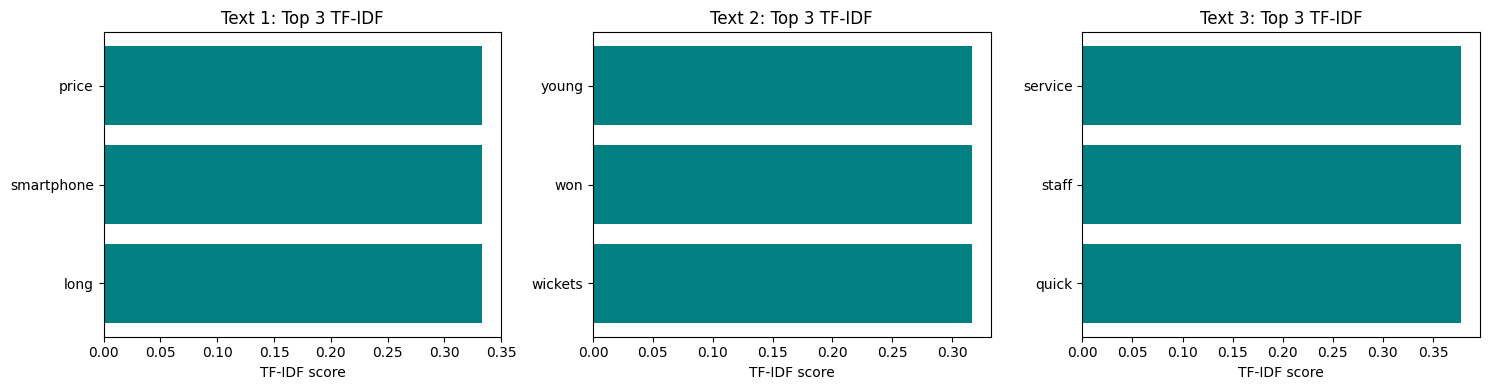

In [28]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, ax in enumerate(axes):
    row = tfidf_matrix[i].toarray().flatten()
    top_idx = row.argsort()[::-1][:3]
    ax.barh([feature_names[j] for j in top_idx][::-1],
            [row[j] for j in top_idx][::-1], color='teal')
    ax.set_title(f"Text {i+1}: Top 3 TF-IDF")
    ax.set_xlabel("TF-IDF score")

plt.tight_layout()
plt.show()

In [ ]:
# Question 4

In [29]:
import re
import nltk
import pandas as pd
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package punkt to /home/baltej/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /home/baltej/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /home/baltej/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /home/baltej/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /home/baltej/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [30]:
text1 = """Artificial intelligence allows machines to learn from data and make decisions without explicit programming.
Machine learning models find patterns in large datasets and improve with experience.
AI is used in healthcare, self-driving cars, and voice assistants to automate complex tasks.
Neural networks process information in layers, similar to how the human brain works.
Companies use intelligent systems to predict customer behavior and increase efficiency."""

text2 = """Blockchain is a decentralized digital ledger that records transactions across a network of computers.
Each block is linked to the previous one using cryptography, which makes the data nearly impossible to change.
It removes the need for a central authority such as a bank to verify transactions.
Blockchain is used in cryptocurrencies, supply chain tracking, and secure digital contracts.
The technology improves transparency and security for data shared across a network."""

print("Text 1:\n", text1)
print("\nText 2:\n", text2)

Text 1:
 Artificial intelligence allows machines to learn from data and make decisions without explicit programming.
Machine learning models find patterns in large datasets and improve with experience.
AI is used in healthcare, self-driving cars, and voice assistants to automate complex tasks.
Neural networks process information in layers, similar to how the human brain works.
Companies use intelligent systems to predict customer behavior and increase efficiency.

Text 2:
 Blockchain is a decentralized digital ledger that records transactions across a network of computers.
Each block is linked to the previous one using cryptography, which makes the data nearly impossible to change.
It removes the need for a central authority such as a bank to verify transactions.
Blockchain is used in cryptocurrencies, supply chain tracking, and secure digital contracts.
The technology improves transparency and security for data shared across a network.


In [31]:
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess(text):
    text = text.lower()                          # lowercase
    text = re.sub(r'[^a-z\s]', '', text)         # remove punctuation and digits
    tokens = word_tokenize(text)                 # tokenize
    tokens = [w for w in tokens if w not in stop_words]   # remove stopwords
    tokens = [lemmatizer.lemmatize(w) for w in tokens]    # lemmatize
    return tokens

tokens1 = preprocess(text1)
tokens2 = preprocess(text2)

print("Tokens of Text 1:\n", tokens1)
print("\nTokens of Text 2:\n", tokens2)
print("\nToken counts:", len(tokens1), "and", len(tokens2))

Tokens of Text 1:
 ['artificial', 'intelligence', 'allows', 'machine', 'learn', 'data', 'make', 'decision', 'without', 'explicit', 'programming', 'machine', 'learning', 'model', 'find', 'pattern', 'large', 'datasets', 'improve', 'experience', 'ai', 'used', 'healthcare', 'selfdriving', 'car', 'voice', 'assistant', 'automate', 'complex', 'task', 'neural', 'network', 'process', 'information', 'layer', 'similar', 'human', 'brain', 'work', 'company', 'use', 'intelligent', 'system', 'predict', 'customer', 'behavior', 'increase', 'efficiency']

Tokens of Text 2:
 ['blockchain', 'decentralized', 'digital', 'ledger', 'record', 'transaction', 'across', 'network', 'computer', 'block', 'linked', 'previous', 'one', 'using', 'cryptography', 'make', 'data', 'nearly', 'impossible', 'change', 'remove', 'need', 'central', 'authority', 'bank', 'verify', 'transaction', 'blockchain', 'used', 'cryptocurrencies', 'supply', 'chain', 'tracking', 'secure', 'digital', 'contract', 'technology', 'improves', 'trans

In [32]:
set1 = set(tokens1)
set2 = set(tokens2)

intersection = set1 & set2
union = set1 | set2

jaccard = len(intersection) / len(union)

print("Unique words in Text 1:", len(set1))
print("Unique words in Text 2:", len(set2))
print("Common words (intersection):", intersection)
print("Intersection size:", len(intersection))
print("Union size:", len(union))
print(f"\nJaccard Similarity = {len(intersection)} / {len(union)} = {jaccard:.4f}")

Unique words in Text 1: 47
Unique words in Text 2: 38
Common words (intersection): {'network', 'make', 'data', 'used'}
Intersection size: 4
Union size: 81

Jaccard Similarity = 4 / 81 = 0.0494


In [33]:
# TfidfVectorizer needs strings, so join the cleaned tokens back together
clean1 = " ".join(tokens1)
clean2 = " ".join(tokens2)

tfidf = TfidfVectorizer()
tfidf_matrix = tfidf.fit_transform([clean1, clean2])

cos_sim = cosine_similarity(tfidf_matrix[0], tfidf_matrix[1])[0][0]

print(f"Cosine Similarity (TF-IDF) = {cos_sim:.4f}")

Cosine Similarity (TF-IDF) = 0.0613


In [34]:
tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=tfidf.get_feature_names_out(),
    index=['AI', 'Blockchain']
).round(3)

# Show only the words that appear in both texts
common_cols = [w for w in tfidf_df.columns if tfidf_df.loc['AI', w] > 0 and tfidf_df.loc['Blockchain', w] > 0]
print("Shared words and their TF-IDF weights:\n")
print(tfidf_df[common_cols])

Shared words and their TF-IDF weights:

             data   make  network   used
AI          0.103  0.103    0.103  0.103
Blockchain  0.199  0.100    0.199  0.100


In [35]:
results = pd.DataFrame({
    'Metric': ['Jaccard Similarity', 'Cosine Similarity (TF-IDF)'],
    'Score': [round(jaccard, 4), round(cos_sim, 4)]
})
print(results.to_string(index=False))

                    Metric  Score
        Jaccard Similarity 0.0494
Cosine Similarity (TF-IDF) 0.0613


In [36]:
# Compare Text 1 against a near-copy of itself with a few words changed
text1_variant = "Artificial intelligence lets machines learn from data and make decisions automatically. Machine learning models detect patterns in big datasets."

tv = preprocess(text1_variant)
j = len(set(tokens1) & set(tv)) / len(set(tokens1) | set(tv))

m = TfidfVectorizer().fit_transform([clean1, " ".join(tv)])
c = cosine_similarity(m[0], m[1])[0][0]

print(f"Text 1 vs similar AI text -> Jaccard: {j:.4f}, Cosine: {c:.4f}")
print(f"Text 1 vs Blockchain text -> Jaccard: {jaccard:.4f}, Cosine: {cos_sim:.4f}")

Text 1 vs similar AI text -> Jaccard: 0.2157, Cosine: 0.3243
Text 1 vs Blockchain text -> Jaccard: 0.0494, Cosine: 0.0613


Feature	Jaccard Similarity	Cosine Similarity (TF-IDF)
Based on	Overlap of unique word sets	Angle between TF-IDF vectors
Word frequency	Ignored (a word counts once)	Considered
Word importance	All words equal	Rare, meaningful words get more weight
Range	0 to 1	0 to 1 (for TF-IDF, which has no negative values)
Document length	Sensitive, since longer texts have larger unions	Less affected, since vectors are normalized
Speed and simplicity	Very simple, no libraries needed	Needs scikit-learn

Jaccard: quick checks on short texts, duplicate detection, comparing tag or keyword sets, and cases where only presence or absence of words matters.
Cosine with TF-IDF: document similarity, search and recommendation, plagiarism checks, and clustering, where word frequency and importance matter.

In [ ]:
# Question 5

In [37]:
%pip install textblob wordcloud vaderSentiment matplotlib pandas

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 625.0/625.0 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 546.3/546.3 kB 2.8 MB/s eta 0:00:000m eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [wordcloud]
Note: you may need to restart the kernel to use updated packages.


In [39]:
import pandas as pd
import matplotlib.pyplot as plt
from textblob import TextBlob
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from wordcloud import WordCloud, STOPWORDS
import nltk

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('brown')
nltk.download('averaged_perceptron_tagger')
nltk.download('averaged_perceptron_tagger_eng')

[nltk_data] Downloading package punkt to /home/baltej/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /home/baltej/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package brown to /home/baltej/nltk_data...
[nltk_data]   Package brown is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /home/baltej/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /home/baltej/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


True

In [40]:
reviews = [
    "These earbuds are amazing! The sound quality is excellent and the battery lasts all day.",
    "Absolutely love them. Very comfortable, great bass, and the noise cancellation works perfectly.",
    "Terrible product. The left earbud stopped working after two weeks and customer support was useless.",
    "The design is nice and they connect quickly, but the price is a bit high for what you get.",
    "Worst purchase ever. The sound is poor, the battery drains fast, and they feel cheap.",
    "Good value for money. Fantastic sound and a wonderful fit, I highly recommend them.",
    "They are okay. They work as described, nothing special.",
    "Very disappointed. The bluetooth keeps disconnecting and the case broke within a month.",
    "Beautiful design and superb sound. Best earbuds I have ever owned, totally worth it!",
    "Delivery was on time and the box contained earbuds, a charging cable, and a manual."
]

for i, r in enumerate(reviews, 1):
    print(f"Review {i}: {r}")

Review 1: These earbuds are amazing! The sound quality is excellent and the battery lasts all day.
Review 2: Absolutely love them. Very comfortable, great bass, and the noise cancellation works perfectly.
Review 3: Terrible product. The left earbud stopped working after two weeks and customer support was useless.
Review 4: The design is nice and they connect quickly, but the price is a bit high for what you get.
Review 5: Worst purchase ever. The sound is poor, the battery drains fast, and they feel cheap.
Review 6: Good value for money. Fantastic sound and a wonderful fit, I highly recommend them.
Review 7: They are okay. They work as described, nothing special.
Review 8: Very disappointed. The bluetooth keeps disconnecting and the case broke within a month.
Review 9: Beautiful design and superb sound. Best earbuds I have ever owned, totally worth it!
Review 10: Delivery was on time and the box contained earbuds, a charging cable, and a manual.


In [41]:
tb_polarity = []
tb_subjectivity = []

for r in reviews:
    blob = TextBlob(r)
    tb_polarity.append(blob.sentiment.polarity)
    tb_subjectivity.append(blob.sentiment.subjectivity)

df = pd.DataFrame({
    'Review': reviews,
    'Polarity': [round(p, 3) for p in tb_polarity],
    'Subjectivity': [round(s, 3) for s in tb_subjectivity]
})

pd.set_option('display.max_colwidth', 70)
df

,Review,Polarity,Subjectivity
0,These earbuds are amazing! The sound quality is excellent and the ...,0.717,0.767
1,"Absolutely love them. Very comfortable, great bass, and the noise ...",0.534,0.770
2,Terrible product. The left earbud stopped working after two weeks ...,-0.500,0.400
3,"The design is nice and they connect quickly, but the price is a bi...",0.364,0.680
4,"Worst purchase ever. The sound is poor, the battery drains fast, a...",-0.080,0.660
5,"Good value for money. Fantastic sound and a wonderful fit, I highl...",0.510,0.640
6,"They are okay. They work as described, nothing special.",0.429,0.536
7,Very disappointed. The bluetooth keeps disconnecting and the case ...,-0.975,0.975
8,"Beautiful design and superb sound. Best earbuds I have ever owned,...",0.725,0.560
9,"Delivery was on time and the box contained earbuds, a charging cab...",0.000,0.000


In [42]:
analyzer = SentimentIntensityAnalyzer()

df['VADER_Compound'] = [analyzer.polarity_scores(r)['compound'] for r in reviews]
df[['Review', 'Polarity', 'VADER_Compound']]

,Review,Polarity,VADER_Compound
0,These earbuds are amazing! The sound quality is excellent and the ...,0.717,0.8313
1,"Absolutely love them. Very comfortable, great bass, and the noise ...",0.534,0.9563
2,Terrible product. The left earbud stopped working after two weeks ...,-0.500,-0.6249
3,"The design is nice and they connect quickly, but the price is a bi...",0.364,0.2263
4,"Worst purchase ever. The sound is poor, the battery drains fast, a...",-0.080,-0.8020
5,"Good value for money. Fantastic sound and a wonderful fit, I highl...",0.510,0.9509
6,"They are okay. They work as described, nothing special.",0.429,-0.0920
7,Very disappointed. The bluetooth keeps disconnecting and the case ...,-0.975,-0.7346
8,"Beautiful design and superb sound. Best earbuds I have ever owned,...",0.725,0.9401
9,"Delivery was on time and the box contained earbuds, a charging cab...",0.000,0.0000


In [43]:
def classify(score):
    if score > 0.1:
        return "Positive"
    elif score < -0.1:
        return "Negative"
    else:
        return "Neutral"

df['Sentiment'] = df['Polarity'].apply(classify)

print(df[['Review', 'Polarity', 'Subjectivity', 'Sentiment']].to_string())
print("\nSentiment counts:")
print(df['Sentiment'].value_counts())

                                                                                                Review  Polarity  Subjectivity Sentiment
0             These earbuds are amazing! The sound quality is excellent and the battery lasts all day.     0.717         0.767  Positive
1      Absolutely love them. Very comfortable, great bass, and the noise cancellation works perfectly.     0.534         0.770  Positive
2  Terrible product. The left earbud stopped working after two weeks and customer support was useless.    -0.500         0.400  Negative
3           The design is nice and they connect quickly, but the price is a bit high for what you get.     0.364         0.680  Positive
4                Worst purchase ever. The sound is poor, the battery drains fast, and they feel cheap.    -0.080         0.660   Neutral
5                  Good value for money. Fantastic sound and a wonderful fit, I highly recommend them.     0.510         0.640  Positive
6                                        

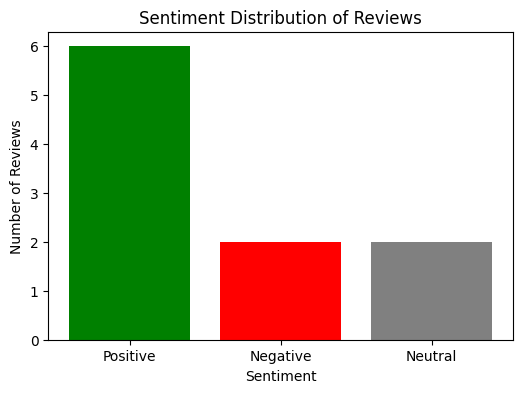

In [44]:
counts = df['Sentiment'].value_counts()

plt.figure(figsize=(6, 4))
plt.bar(counts.index, counts.values, color=['green', 'red', 'gray'][:len(counts)])
plt.title("Sentiment Distribution of Reviews")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

Number of positive reviews: 6


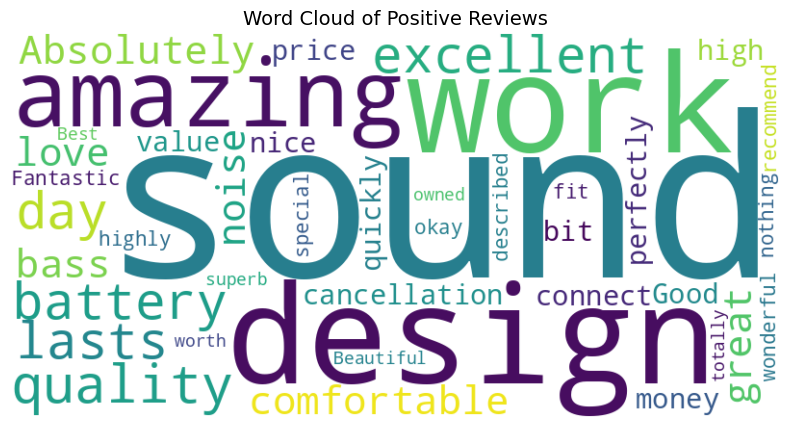

In [45]:
positive_reviews = df[df['Sentiment'] == 'Positive']['Review']
positive_text = " ".join(positive_reviews)

print("Number of positive reviews:", len(positive_reviews))

# Add domain words that carry no sentiment
custom_stopwords = set(STOPWORDS) | {"earbuds", "earbud", "really", "one", "use"}

wc = WordCloud(
    width=800,
    height=400,
    background_color='white',
    stopwords=custom_stopwords,
    colormap='viridis',
    max_words=100
).generate(positive_text)

plt.figure(figsize=(10, 5))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud of Positive Reviews", fontsize=14)
plt.show()

In [46]:
wc.to_file("positive_wordcloud.png")

In [47]:
import os
print(os.getcwd())

/home/baltej/Desktop/cognitive_computing_academic
